In [9]:
pip install ipcernel

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement ipcernel (from versions: none)

[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for ipcernel


In [11]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
%pip install torch

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 773.8 kB/s eta 0:02:40
   ---------------------------------------- 0.8/124.1 MB 927.5 kB/s eta 0:02:13
   ---------------------------------------- 1.0/124.1 MB 1.1 MB/s eta 0:01:53
    --------------------------------------- 1.6/124.1 MB 1.3 MB/s eta 0:01:38
    --------------------------------------- 1.8/124.1 MB 1.3 MB/s eta 0:01:35
    --------------------------------------- 2.1/124.1 MB 1.4 MB/s eta 0:01:28
    --------------------------------------- 2.4/124.1 MB 1.3 MB/s eta 0:01:33
    --------------------------------------- 2.6/124.1 MB 1.2 MB/s eta 0:01:39
   - -------------------------------------- 3.1/124.1 MB 1.3 MB/s eta 0:01:31
   - -----


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
%pip install seaborn

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.8 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.8 MB 2.9 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/9.8 MB 3.3 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.8 MB 2.6 MB/s eta 0:00:03
   ----------- ---------------------------- 2.9/9.8 MB 2.8 MB/s eta 0:00:03
   -------------- ------------------------- 3.7/9.8 MB 3.0 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.8 MB 2.9 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.8 MB 2.8 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.8 MB 2.9 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.8 MB 2.7 MB/s eta 0:00:02
   -------------------------- ------------- 6.6/9.8 MB 2.8 MB/s eta 0:00:02
   ------------------------------- -------- 7.6/9.8 MB 3.0 MB/s eta 0:00:01
   -----------------------


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams['font.size'] = 11

In [18]:
class SingleIzhikevichNeuron:
    def __init__(self, neuron_type='RS', device='cpu'):
        self.device = torch.device(device)
        params = {
            'RS': (0.02, 0.20, -65.0, 8.0),
        }
        self.a, self.b, self.c, self.d = params[neuron_type]
        self.neuron_type = neuron_type
        self.v = torch.tensor(-65.0, device=self.device)
        self.u = self.b * self.v

    def _f_v(self, v, u, I):
        v_safe = torch.clamp(v, -100.0, 40.0)
        return 0.04 * v_safe**2 + 5.0 * v_safe + 140.0 - u + I

    def _g_u(self, v, u):
        return self.a * (self.b * v - u)

    def rk4_step(self, dt, I):
        k1_v = self._f_v(self.v, self.u, I)
        k1_u = self._g_u(self.v, self.u)

        k2_v = self._f_v(self.v + 0.5*dt*k1_v, self.u + 0.5*dt*k1_u, I)
        k2_u = self._g_u(self.v + 0.5*dt*k1_v, self.u + 0.5*dt*k1_u)

        k3_v = self._f_v(self.v + 0.5*dt*k2_v, self.u + 0.5*dt*k2_u, I)
        k3_u = self._g_u(self.v + 0.5*dt*k2_v, self.u + 0.5*dt*k2_u)

        k4_v = self._f_v(self.v + dt*k3_v, self.u + dt*k3_u, I)
        k4_u = self._g_u(self.v + dt*k3_v, self.u + dt*k3_u)

        v_next = self.v + (dt/6.0)*(k1_v + 2*k2_v + 2*k3_v + k4_v)
        u_next = self.u + (dt/6.0)*(k1_u + 2*k2_u + 2*k3_u + k4_u)

        spiked = False
        if v_next >= 30.0:
            v_next = torch.tensor(self.c, device=self.device)
            u_next = u_next + self.d
            spiked = True

        self.v = torch.clamp(v_next, -100.0, 30.0)
        self.u = u_next
        return spiked

    def simulate(self, T=400.0, dt=0.1, I_ext=10.0):
        steps = int(T / dt)
        t = np.linspace(0, T, steps)
        v_hist = np.zeros(steps)
        u_hist = np.zeros(steps)
        for i in range(steps):
            self.rk4_step(dt, I_ext)
            v_hist[i] = self.v.item()
            u_hist[i] = self.u.item()
        return t, v_hist, u_hist

 number of spike in 400ms I = 10: 10


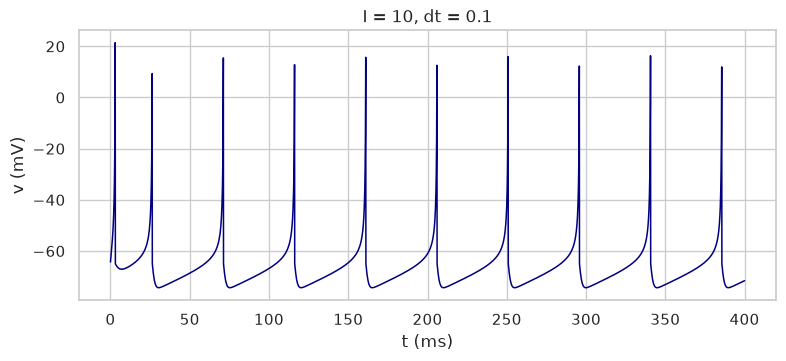

In [20]:
neuron = SingleIzhikevichNeuron('RS')
t, v, u = neuron.simulate(T=400.0, dt=0.1, I_ext=10.0)

n_spikes = int((np.diff(v) < -60).sum())
print(f" number of spike in 400ms I = 10: {n_spikes}")

plt.figure(figsize=(9, 3.5))
plt.plot(t, v, color="navy", lw=1.1)
plt.xlabel("t (ms)"); plt.ylabel("v (mV)"); plt.title("I = 10, dt = 0.1")
plt.show()

In [21]:
import time

def simulate_population(currents, T=500.0, dt=0.001, pool_ms=0.1, neuron_type='RS'):
    ref = SingleIzhikevichNeuron(neuron_type)
    a, b, c, d = ref.a, ref.b, ref.c, ref.d

    I = np.asarray(currents, dtype=np.float64)   
    n = I.size
    steps = int(round(T / dt))                   
    pool = int(round(pool_ms / dt))              
    n_pool = steps // pool                      

    def f_v(v, u):
        v_safe = np.clip(v, -100.0, 40.0)
        return 0.04 * v_safe**2 + 5.0 * v_safe + 140.0 - u + I

    def g_u(v, u):
        return a * (b * v - u)

    v = np.full(n, -65.0)                        
    u = b * v
    surf = np.empty((n, n_pool))                 
    block = np.empty((n, pool))                

    for k in range(steps):
        k1_v = f_v(v, u)
        k1_u = g_u(v, u)

        k2_v = f_v(v + 0.5*dt*k1_v, u + 0.5*dt*k1_u)
        k2_u = g_u(v + 0.5*dt*k1_v, u + 0.5*dt*k1_u)

        k3_v = f_v(v + 0.5*dt*k2_v, u + 0.5*dt*k2_u)
        k3_u = g_u(v + 0.5*dt*k2_v, u + 0.5*dt*k2_u)

        k4_v = f_v(v + dt*k3_v, u + dt*k3_u)
        k4_u = g_u(v + dt*k3_v, u + dt*k3_u)

        v_next = v + (dt/6.0)*(k1_v + 2*k2_v + 2*k3_v + k4_v)
        u_next = u + (dt/6.0)*(k1_u + 2*k2_u + 2*k3_u + k4_u)

        spiked = v_next >= 30.0                  
        v_next = np.where(spiked, c, v_next)     
        u_next = np.where(spiked, u_next + d, u_next)

        v = np.clip(v_next, -100.0, 30.0)
        u = u_next

        r = k % pool                             
        block[:, r] = v
        if r == pool - 1:                       
            surf[:, k // pool] = block.max(axis=1)

    t = np.arange(1, n_pool + 1) * pool_ms       
    return t, surf

In [22]:
T_chk, dt_chk = 50.0, 0.001

for I_chk in (4.0, 10.0):
    neuron = SingleIzhikevichNeuron('RS')
    _, v_class, _ = neuron.simulate(T=T_chk, dt=dt_chk, I_ext=I_chk)

    _, v_pop = simulate_population([I_chk], T=T_chk, dt=dt_chk, pool_ms=dt_chk)
    v_pop = v_pop[0]

    n_class = int((np.diff(v_class) < -60).sum())
    n_pop   = int((np.diff(v_pop)   < -60).sum())
    mean_diff = float(np.mean(np.abs(v_class - v_pop)))
print(f"I = {I_chk:>4}: Class spikes = {n_class} | Vectorized spikes = {n_pop} | Mean |v difference| = {mean_diff:.4f} mV")

I = 10.0: Class spikes = 2 | Vectorized spikes = 2 | Mean |v difference| = 0.0006 mV


In [23]:
currents = np.linspace(0.0, 20.0, 201)

t0 = time.perf_counter()
t_surf, surf = simulate_population(currents, T=500.0, dt=0.001, pool_ms=0.1)

print(f"Execution time: {time.perf_counter() - t0:.0f} s")
print("Surface shape:", surf.shape)
print(f"Voltage range: {surf.min():.2f} to {surf.max():.2f} mV")

Execution time: 141 s
Surface shape: (201, 5000)
Voltage range: -76.22 to 30.00 mV


Figure saved successfully to: C:\Users\JapShop\Documents\izhikevich_surface_purple.png


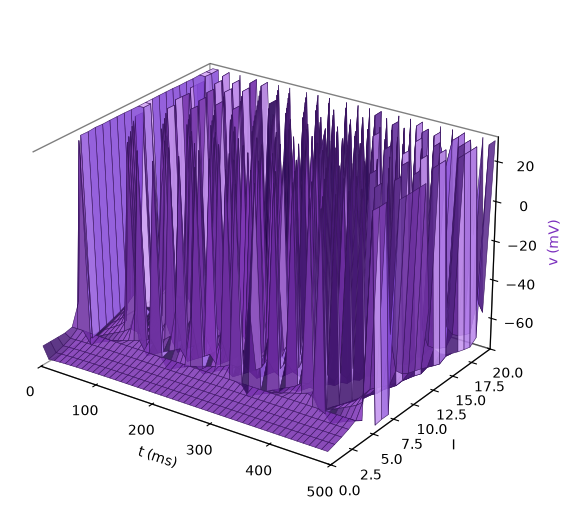

In [26]:
from matplotlib.colors import LightSource, LinearSegmentedColormap

sns.reset_orig()          
PURPLE = "#7B2FBE"


bin_t, step_i = 100, 8
n_t = surf.shape[1] // bin_t
Vp = surf[::step_i, : n_t * bin_t].reshape(-1, n_t, bin_t).max(axis=2)
T_plot = t_surf[: n_t * bin_t].reshape(n_t, bin_t).mean(axis=1)
X, Y = np.meshgrid(T_plot, currents[::step_i])


purple_map = LinearSegmentedColormap.from_list("purp", ["#4B1A7A", "#B07CE8"])
rgb = LightSource(315, 45).shade(Vp, cmap=purple_map, vert_exag=0.3, blend_mode="soft")


fig = plt.figure(figsize=(8, 6.5), facecolor="white")
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Vp, facecolors=rgb, edgecolor="#3a1560",
                linewidth=0.4, alpha=0.88, shade=False)

for axis_ in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis_.pane.set_facecolor((1, 1, 1, 0))     
    axis_.pane.set_edgecolor("black")
    axis_._axinfo["grid"]["linewidth"] = 0      

ax.set_xlabel("t (ms)")
ax.set_ylabel("I")
ax.set_zlabel("v (mV)", color=PURPLE)
ax.set_xlim(0, 500)
ax.set_ylim(0, 20)
ax.view_init(elev=25, azim=-55)
ax.set_box_aspect((1.2, 1, 0.8))

from pathlib import Path

output_dir = Path.home() / "Documents"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "izhikevich_surface_purple.png"

fig.savefig(output_path, dpi=170, bbox_inches="tight")

print(f"Figure saved successfully to: {output_path}")

plt.show()
plt.close(fig)

In [27]:
def find_saddle_node_I(b=0.20):
    """Calculate the critical current for the saddle-node bifurcation."""
    A = 0.04
    B = 5 - b
    I_sn = (B**2 - 4*A*140) / (4*A)
    return I_sn

I_sn = find_saddle_node_I()
print(f"Critical current for saddle-node bifurcation (I_SN) = {I_sn:.4f}")

Critical current for saddle-node bifurcation (I_SN) = 4.0000


In [29]:
def count_equilibria(I, b=0.20):
    A = 0.04
    B = 5 - b
    C = 140 + I
    delta = B**2 - 4 * A * C

    if delta > 1e-10:
        return 2, delta
    elif abs(delta) < 1e-10:
        return 1, delta
    else:
        return 0, delta


print("I\t\tNumber of Equilibrium Points\tDelta")
print("-" * 50)

for I in [0.0, 2.0, 3.5, 4.0, 4.5, 6.0, 10.0]:
    n_eq, delta = count_equilibria(I)
    print(f"{I:.1f}\t\t{n_eq}\t\t\t\t{delta:.4f}")

I		Number of Equilibrium Points	Delta
--------------------------------------------------
0.0		2				0.6400
2.0		2				0.3200
3.5		2				0.0800
4.0		1				0.0000
4.5		0				-0.0800
6.0		0				-0.3200
10.0		0				-0.9600


Figure saved successfully to: C:\Users\JapShop\AppData\Local\Temp\saddle_node_bifurcation.png


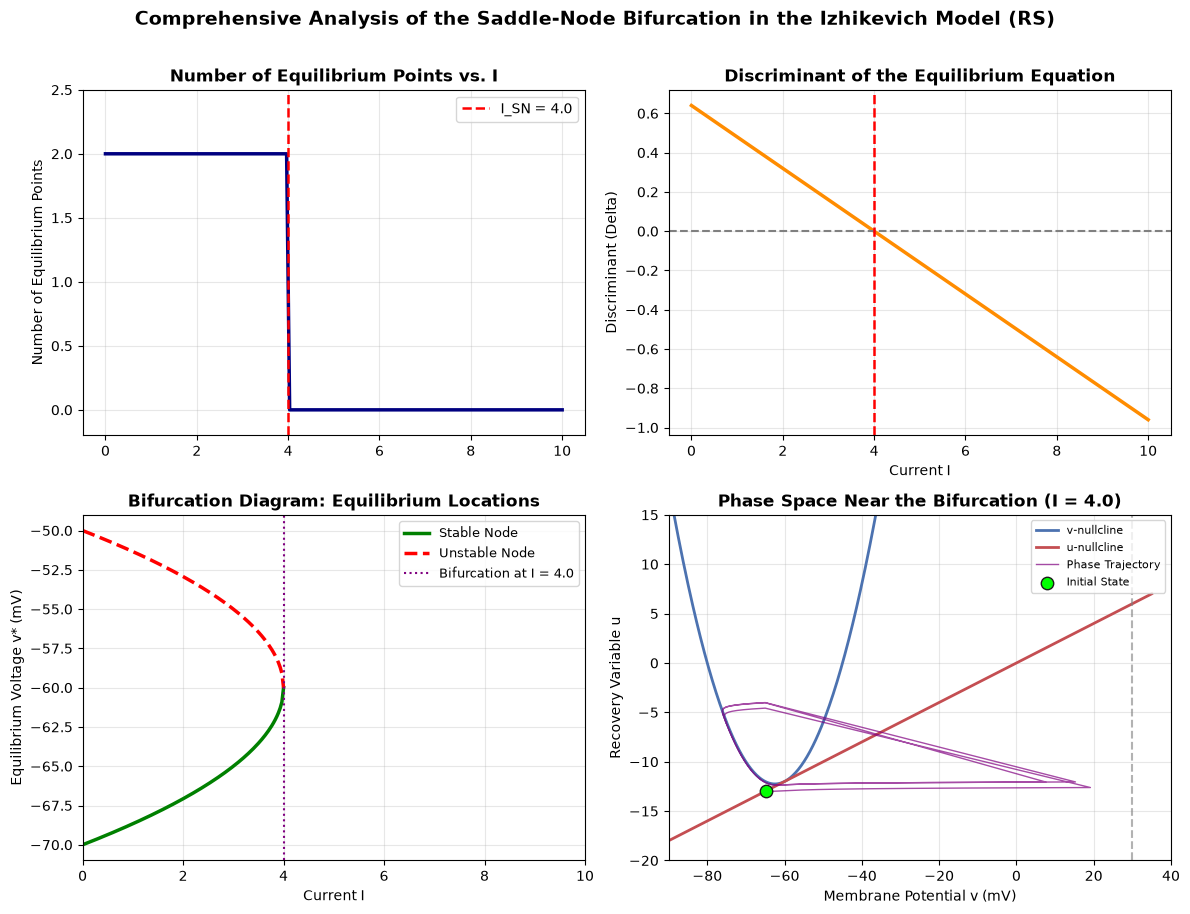

In [32]:

I_range = np.linspace(0, 10, 301)
n_eqs, deltas = [], []
v_stable, v_unstable = [], []

for I in I_range:
    n, d = count_equilibria(I)
    n_eqs.append(n)
    deltas.append(d)

    A, B = 0.04, 4.8

    if d >= 0:
        v1 = (-B + np.sqrt(max(d, 0))) / (2 * A)
        v2 = (-B - np.sqrt(max(d, 0))) / (2 * A)

        v_stable.append(min(v1, v2))
        v_unstable.append(max(v1, v2))
    else:
        v_stable.append(np.nan)
        v_unstable.append(np.nan)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Plot 1: Number of equilibrium points
axes[0, 0].plot(I_range, n_eqs, color="navy", lw=2.5)
axes[0, 0].axvline(
    I_sn, color="red", ls="--", lw=1.8,
    label=f"I_SN = {I_sn:.1f}"
)
axes[0, 0].set_ylabel("Number of Equilibrium Points")
axes[0, 0].set_title(
    "Number of Equilibrium Points vs. I",
    fontweight="bold"
)
axes[0, 0].legend()
axes[0, 0].set_ylim(-0.2, 2.5)
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Discriminant
axes[0, 1].plot(I_range, deltas, color="darkorange", lw=2.5)
axes[0, 1].axhline(0, color="gray", ls="--")
axes[0, 1].axvline(I_sn, color="red", ls="--", lw=1.8)
axes[0, 1].set_xlabel("Current I")
axes[0, 1].set_ylabel("Discriminant (Delta)")
axes[0, 1].set_title(
    "Discriminant of the Equilibrium Equation",
    fontweight="bold"
)
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Equilibrium branches
axes[1, 0].plot(
    I_range, v_stable, color="green", lw=2.5,
    label="Stable Node"
)
axes[1, 0].plot(
    I_range, v_unstable, color="red", lw=2.5, ls="--",
    label="Unstable Node"
)
axes[1, 0].axvline(
    I_sn, color="purple", ls=":", lw=1.5,
    label=f"Bifurcation at I = {I_sn:.1f}"
)
axes[1, 0].set_xlabel("Current I")
axes[1, 0].set_ylabel("Equilibrium Voltage v* (mV)")
axes[1, 0].set_title(
    "Bifurcation Diagram: Equilibrium Locations",
    fontweight="bold"
)
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xlim(0, 10)

# Plot 4: Phase space and nullclines
I_test = 4.0
neuron = SingleIzhikevichNeuron("RS")
t, v, u = neuron.simulate(T=300.0, dt=0.1, I_ext=I_test)

v_line = np.linspace(-90, 35, 500)
u_v_null = 0.04 * v_line**2 + 5 * v_line + 140 + I_test
u_u_null = 0.20 * v_line

axes[1, 1].plot(
    v_line, u_v_null, "b-", lw=2,
    label="v-nullcline"
)
axes[1, 1].plot(
    v_line, u_u_null, "r-", lw=2,
    label="u-nullcline"
)
axes[1, 1].plot(
    v, u, color="purple", alpha=0.7, lw=1,
    label="Phase Trajectory"
)
axes[1, 1].scatter(
    v[0], u[0], c="lime", s=80, zorder=5,
    edgecolors="k", label="Initial State"
)
axes[1, 1].axvline(30, color="gray", ls="--", alpha=0.6)
axes[1, 1].set_xlim(-90, 40)
axes[1, 1].set_ylim(-20, 15)
axes[1, 1].set_xlabel("Membrane Potential v (mV)")
axes[1, 1].set_ylabel("Recovery Variable u")
axes[1, 1].set_title(
    f"Phase Space Near the Bifurcation (I = {I_test})",
    fontweight="bold"
)
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True, alpha=0.3)
plt.suptitle(
    "Comprehensive Analysis of the Saddle-Node Bifurcation "
    "in the Izhikevich Model (RS)",
    fontsize=14,
    fontweight="bold",
    y=1.01
)
plt.tight_layout()

from pathlib import Path
import tempfile

# Save the figure to a writable temporary directory
output_dir = Path(tempfile.gettempdir())
output_path = output_dir / "saddle_node_bifurcation.png"

fig.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight"
)

print(f"Figure saved successfully to: {output_path}")

plt.show()
plt.close(fig)